## Import dan Konfigurasi

In [1]:
import os, json, time, random
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
from sklearn.metrics import (
    confusion_matrix, classification_report,
    accuracy_score, precision_score, recall_score, f1_score
)
import seaborn as sns

# ---- Hyperparameter & Path ----
SEED        = 42
BATCH_SIZE  = 32
LR          = 0.0005
MAX_EPOCHS  = 60
PATIENCE    = 15          # early stopping
NUM_CLASSES = 4
IMG_SIZE    = 224
MODEL_NAME  = 'cnn_base'

NOTEBOOK_DIR = Path(r'C:\Users\Bunga Alyssa\OneDrive\文档\DS\smt  7\deep l\uas\frontend\coin_new\notebook')
DIAGRAM_DIR  = Path(r'C:\Users\Bunga Alyssa\OneDrive\文档\DS\smt  7\deep l\uas\frontend\coin_new\diagram')
DIAGRAM_DIR.mkdir(parents=True, exist_ok=True)

# ---- Seed ----
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')
print(f'PyTorch: {torch.__version__}')

Device: cpu
PyTorch: 2.12.0+cpu


## Muat Split

In [2]:
df_split = pd.read_csv(NOTEBOOK_DIR / 'split.csv')

CLASSES = sorted(df_split['label'].unique())
CLASS2IDX = {c: i for i, c in enumerate(CLASSES)}
IDX2CLASS = {i: c for c, i in CLASS2IDX.items()}

df_train = df_split[df_split['subset'] == 'train'].reset_index(drop=True)
df_val   = df_split[df_split['subset'] == 'val'].reset_index(drop=True)
df_test  = df_split[df_split['subset'] == 'test'].reset_index(drop=True)

print(f'Classes: {CLASSES}')
print(f'Train: {len(df_train)} | Val: {len(df_val)} | Test: {len(df_test)}')
print('\nTrain distribution:')
print(df_train['label'].value_counts())
print('\nVal distribution:')
print(df_val['label'].value_counts())
print('\nTest distribution:')
print(df_test['label'].value_counts())

Classes: ['Rp100', 'Rp1000', 'Rp200', 'Rp500']
Train: 414 | Val: 89 | Test: 89

Train distribution:
label
Rp200     114
Rp100     102
Rp500      99
Rp1000     99
Name: count, dtype: int64

Val distribution:
label
Rp200     24
Rp100     22
Rp500     22
Rp1000    21
Name: count, dtype: int64

Test distribution:
label
Rp200     25
Rp100     22
Rp500     21
Rp1000    21
Name: count, dtype: int64


## Dataset dan DataLoader

In [3]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

train_tf = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0), ratio=(0.9, 1.1)),
    transforms.RandomRotation(360),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.2),
    transforms.GaussianBlur(kernel_size=3, sigma=(0.1, 1.5)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    transforms.RandomErasing(p=0.2, scale=(0.02, 0.2)),
])

val_tf = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

class CoinDataset(Dataset):
    def __init__(self, df, class2idx, transform=None):
        self.df = df.reset_index(drop=True)
        self.class2idx = class2idx
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img = Image.open(row['path']).convert('RGB')
        if self.transform:
            img = self.transform(img)
        label = self.class2idx[row['label']]
        return img, label

train_ds = CoinDataset(df_train, CLASS2IDX, train_tf)
val_ds   = CoinDataset(df_val,   CLASS2IDX, val_tf)
test_ds  = CoinDataset(df_test,  CLASS2IDX, val_tf)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=0, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)

print(f'Train batches: {len(train_loader)} | Val batches: {len(val_loader)} | Test batches: {len(test_loader)}')


Train batches: 13 | Val batches: 3 | Test batches: 3


## Hitung Class Weight

In [4]:
from sklearn.utils.class_weight import compute_class_weight

train_labels = [CLASS2IDX[l] for l in df_train['label']]
cw = compute_class_weight('balanced', classes=np.arange(NUM_CLASSES), y=train_labels)
class_weights = torch.tensor(cw, dtype=torch.float32).to(DEVICE)
print('Class weights:', {IDX2CLASS[i]: round(float(w), 4) for i, w in enumerate(class_weights)})

Class weights: {'Rp100': 1.0147, 'Rp1000': 1.0455, 'Rp200': 0.9079, 'Rp500': 1.0455}


## Definisi Model CNN Base

In [5]:
class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch, pool=True):
        super().__init__()
        layers = [
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        ]
        if pool:
            layers.append(nn.MaxPool2d(2, 2))
        self.block = nn.Sequential(*layers)

    def forward(self, x):
        return self.block(x)

class CNNBase(nn.Module):
    def __init__(self, num_classes=4, dropout=0.5):
        super().__init__()
        self.features = nn.Sequential(
            ConvBlock(3,   32),   # 224->112
            ConvBlock(32,  64),   # 112->56
            ConvBlock(64, 128),   # 56->28
            ConvBlock(128, 256),  # 28->14
        )
        self.gap     = nn.AdaptiveAvgPool2d(1)
        self.dropout = nn.Dropout(dropout)
        self.fc      = nn.Linear(256, num_classes)

    def forward(self, x):
        x = self.features(x)
        x = self.gap(x)
        x = x.flatten(1)
        x = self.dropout(x)
        return self.fc(x)

model = CNNBase(num_classes=NUM_CLASSES).to(DEVICE)
total_params = sum(p.numel() for p in model.parameters())
print(f'Total parameters: {total_params:,}')
print(model)

Total parameters: 389,924
CNNBase(
  (features): Sequential(
    (0): ConvBlock(
      (block): Sequential(
        (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      )
    )
    (1): ConvBlock(
      (block): Sequential(
        (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      )
    )
    (2): ConvBlock(
      (block): Sequential(
        (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(128, eps=1e-05, momentum

## Training Loop

In [6]:
criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = optim.Adam(model.parameters(), lr=LR)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=5)

history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
best_val_loss = float('inf')
patience_counter = 0
best_model_path = DIAGRAM_DIR / f'best_{MODEL_NAME}.pt'

t_start = time.time()

for epoch in range(1, MAX_EPOCHS + 1):
    # -- Train --
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for imgs, labels in train_loader:
        imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
        optimizer.zero_grad()
        out = model(imgs)
        loss = criterion(out, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * imgs.size(0)
        correct += (out.argmax(1) == labels).sum().item()
        total += imgs.size(0)
    train_loss = running_loss / total
    train_acc  = correct / total

    # -- Val --
    model.eval()
    v_loss, v_correct, v_total = 0.0, 0, 0
    with torch.no_grad():
        for imgs, labels in val_loader:
            imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
            out = model(imgs)
            v_loss    += criterion(out, labels).item() * imgs.size(0)
            v_correct += (out.argmax(1) == labels).sum().item()
            v_total   += imgs.size(0)
    val_loss = v_loss / v_total
    val_acc  = v_correct / v_total

    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['train_acc'].append(train_acc)
    history['val_acc'].append(val_acc)

    scheduler.step(val_loss)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        patience_counter = 0
        torch.save(model.state_dict(), best_model_path)
    else:
        patience_counter += 1

    print(f'Epoch {epoch:3d}/{MAX_EPOCHS} | '
          f'Train Loss: {train_loss:.4f} Acc: {train_acc:.4f} | '
          f'Val Loss: {val_loss:.4f} Acc: {val_acc:.4f} | '
          f'Patience: {patience_counter}/{PATIENCE}')

    if patience_counter >= PATIENCE:
        print(f'Early stopping at epoch {epoch}')
        break

total_train_time = time.time() - t_start
print(f'\nTraining time: {total_train_time:.1f}s ({total_train_time/60:.2f} min)')
print(f'Best val loss: {best_val_loss:.4f}')

C:\Users\Bunga Alyssa\AppData\Local\Programs\Python\Python312\Lib\site-packages\torch\utils\data\dataloader.py:752: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch   1/60 | Train Loss: 1.3118 Acc: 0.3671 | Val Loss: 1.3843 Acc: 0.2360 | Patience: 0/15


Epoch   2/60 | Train Loss: 1.1886 Acc: 0.4517 | Val Loss: 1.1803 Acc: 0.4607 | Patience: 0/15


Epoch   3/60 | Train Loss: 1.1083 Acc: 0.5169 | Val Loss: 0.9759 Acc: 0.6292 | Patience: 0/15


Epoch   4/60 | Train Loss: 0.9858 Acc: 0.5652 | Val Loss: 1.0621 Acc: 0.4719 | Patience: 1/15


Epoch   5/60 | Train Loss: 0.9803 Acc: 0.5773 | Val Loss: 0.8734 Acc: 0.6517 | Patience: 0/15


... (42 outputs left out)

Epoch  48/60 | Train Loss: 0.4838 Acc: 0.8285 | Val Loss: 0.6135 Acc: 0.8090 | Patience: 12/15


Epoch  49/60 | Train Loss: 0.4612 Acc: 0.8430 | Val Loss: 0.6183 Acc: 0.8090 | Patience: 13/15


Epoch  50/60 | Train Loss: 0.5016 Acc: 0.8430 | Val Loss: 0.6179 Acc: 0.8090 | Patience: 14/15


Epoch  51/60 | Train Loss: 0.4819 Acc: 0.8261 | Val Loss: 0.6205 Acc: 0.8090 | Patience: 15/15
Early stopping at epoch 51

Training time: 2077.4s (34.62 min)
Best val loss: 0.5806


## Plot Kurva Training

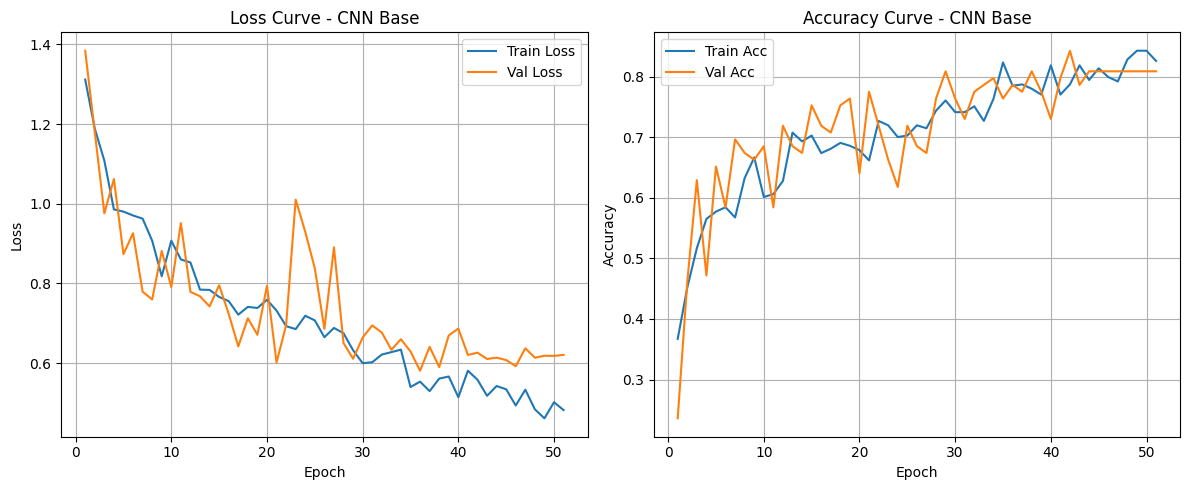

Kurva training tersimpan.


In [7]:
epochs_ran = list(range(1, len(history['train_loss']) + 1))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ax1.plot(epochs_ran, history['train_loss'], label='Train Loss')
ax1.plot(epochs_ran, history['val_loss'],   label='Val Loss')
ax1.set_xlabel('Epoch'); ax1.set_ylabel('Loss')
ax1.set_title('Loss Curve - CNN Base')
ax1.legend(); ax1.grid(True)

ax2.plot(epochs_ran, history['train_acc'], label='Train Acc')
ax2.plot(epochs_ran, history['val_acc'],   label='Val Acc')
ax2.set_xlabel('Epoch'); ax2.set_ylabel('Accuracy')
ax2.set_title('Accuracy Curve - CNN Base')
ax2.legend(); ax2.grid(True)

plt.tight_layout()
plt.savefig(DIAGRAM_DIR / f'kurva_{MODEL_NAME}.png', dpi=150)
plt.show()
print('Kurva training tersimpan.')

## Evaluasi Test Set

In [8]:
# Muat checkpoint terbaik
model.load_state_dict(torch.load(best_model_path, map_location=DEVICE))
model.eval()

all_preds, all_labels = [], []
with torch.no_grad():
    for imgs, labels in test_loader:
        imgs = imgs.to(DEVICE)
        out  = model(imgs)
        preds = out.argmax(1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(labels.numpy())

all_preds  = np.array(all_preds)
all_labels = np.array(all_labels)

acc  = accuracy_score(all_labels, all_preds)
prec = precision_score(all_labels, all_preds, average='macro', zero_division=0)
rec  = recall_score(all_labels, all_preds, average='macro', zero_division=0)
f1   = f1_score(all_labels, all_preds, average='macro', zero_division=0)

print(f'Test Accuracy : {acc:.4f}')
print(f'Test Precision: {prec:.4f}')
print(f'Test Recall   : {rec:.4f}')
print(f'Test F1 (macro): {f1:.4f}')
print()
print(classification_report(all_labels, all_preds, target_names=CLASSES, zero_division=0))

Test Accuracy : 0.7753
Test Precision: 0.7858
Test Recall   : 0.7848
Test F1 (macro): 0.7698

              precision    recall  f1-score   support

       Rp100       0.76      1.00      0.86        22
      Rp1000       0.91      0.95      0.93        21
       Rp200       0.87      0.52      0.65        25
       Rp500       0.61      0.67      0.64        21

    accuracy                           0.78        89
   macro avg       0.79      0.78      0.77        89
weighted avg       0.79      0.78      0.77        89



## Confusion Matrix

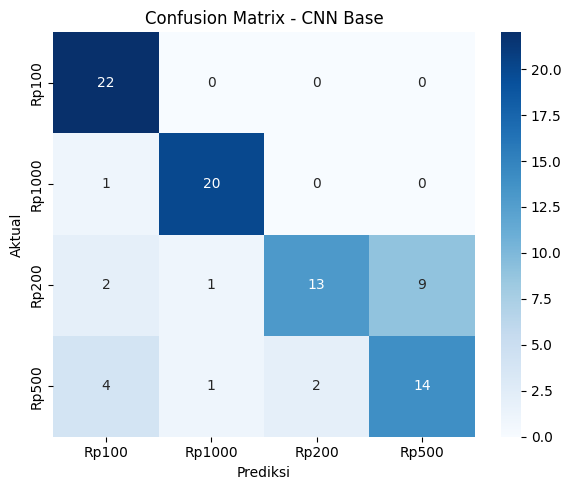

Confusion matrix tersimpan.


In [9]:
cm = confusion_matrix(all_labels, all_preds)

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASSES, yticklabels=CLASSES, ax=ax)
ax.set_xlabel('Prediksi'); ax.set_ylabel('Aktual')
ax.set_title('Confusion Matrix - CNN Base')
plt.tight_layout()
plt.savefig(DIAGRAM_DIR / f'cm_{MODEL_NAME}.png', dpi=150)
plt.show()
print('Confusion matrix tersimpan.')

## Inferensi dan Ukuran Model

In [10]:
# Waktu inferensi rata-rata per gambar
model.eval()
dummy = torch.randn(1, 3, IMG_SIZE, IMG_SIZE).to(DEVICE)
# Warmup
for _ in range(10):
    with torch.no_grad():
        _ = model(dummy)

N_RUNS = 100
t0 = time.time()
for _ in range(N_RUNS):
    with torch.no_grad():
        _ = model(dummy)
infer_time_ms = (time.time() - t0) / N_RUNS * 1000

# Ukuran model
model_size_mb = os.path.getsize(best_model_path) / (1024 ** 2)

print(f'Inferensi rata-rata : {infer_time_ms:.3f} ms/gambar')
print(f'Total parameter     : {total_params:,}')
print(f'Ukuran model (.pt)  : {model_size_mb:.2f} MB')

Inferensi rata-rata : 24.284 ms/gambar
Total parameter     : 389,924
Ukuran model (.pt)  : 1.50 MB


## Contoh Gambar Salah Prediksi

Jumlah salah prediksi: 20


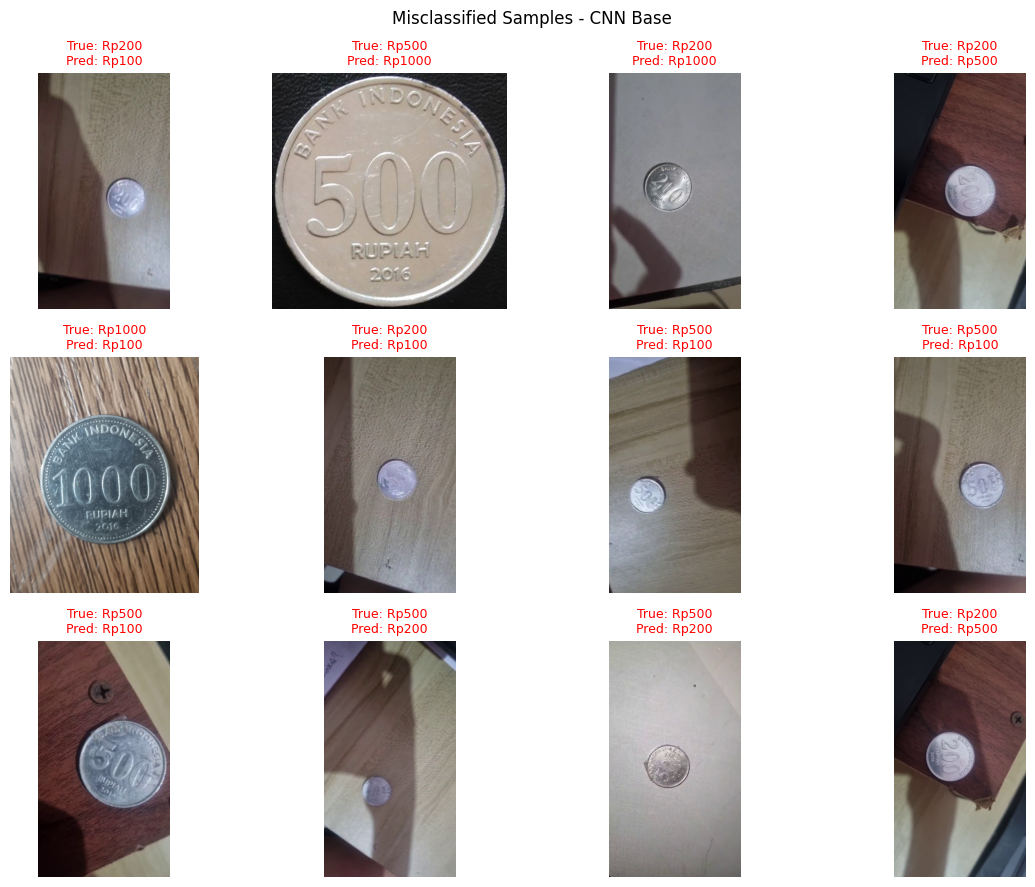

In [11]:
wrong_idxs = np.where(all_preds != all_labels)[0]
print(f'Jumlah salah prediksi: {len(wrong_idxs)}')

show_idxs = wrong_idxs[:12]
if len(show_idxs) > 0:
    ncols = min(4, len(show_idxs))
    nrows = (len(show_idxs) + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 3, nrows * 3))
    axes = np.array(axes).flatten()

    for i, idx in enumerate(show_idxs):
        img_path = df_test.iloc[idx]['path']
        img = Image.open(img_path).convert('RGB')
        axes[i].imshow(img)
        axes[i].set_title(
            f'True: {IDX2CLASS[all_labels[idx]]}\nPred: {IDX2CLASS[all_preds[idx]]}',
            fontsize=9, color='red'
        )
        axes[i].axis('off')

    for j in range(len(show_idxs), len(axes)):
        axes[j].axis('off')

    plt.suptitle('Misclassified Samples - CNN Base', fontsize=12)
    plt.tight_layout()
    plt.savefig(DIAGRAM_DIR / f'misclassified_{MODEL_NAME}.png', dpi=150)
    plt.show()
else:
    print('Tidak ada gambar salah prediksi!')

## Simpan Metrik JSON

In [12]:
# Per-kelas F1
f1_per_class = f1_score(all_labels, all_preds, average=None, zero_division=0).tolist()
prec_per_class = precision_score(all_labels, all_preds, average=None, zero_division=0).tolist()
rec_per_class  = recall_score(all_labels, all_preds, average=None, zero_division=0).tolist()

metrics = {
    'model': MODEL_NAME,
    'accuracy': float(acc),
    'precision_macro': float(prec),
    'recall_macro': float(rec),
    'f1_macro': float(f1),
    'per_class': {
        cls: {
            'precision': round(prec_per_class[i], 4),
            'recall': round(rec_per_class[i], 4),
            'f1': round(f1_per_class[i], 4),
        }
        for i, cls in enumerate(CLASSES)
    },
    'confusion_matrix': cm.tolist(),
    'total_params': total_params,
    'model_size_mb': round(model_size_mb, 4),
    'infer_time_ms': round(infer_time_ms, 4),
    'training_time_s': round(total_train_time, 2),
    'best_epoch': len(history['train_loss']) - patience_counter,
    'history': history,
    'classes': CLASSES,
    'hyperparams': {
        'batch_size': BATCH_SIZE,
        'lr': LR,
        'max_epochs': MAX_EPOCHS,
        'patience': PATIENCE,
        'optimizer': 'Adam',
    }
}

metrics_path = DIAGRAM_DIR / f'metrics_{MODEL_NAME}.json'
with open(metrics_path, 'w') as f:
    json.dump(metrics, f, indent=2)

print(f'Metrik disimpan ke: {metrics_path}')
print(f'\nRingkasan:')
print(f'  Accuracy : {acc:.4f}')
print(f'  Precision: {prec:.4f}')
print(f'  Recall   : {rec:.4f}')
print(f'  F1 Macro : {f1:.4f}')

Metrik disimpan ke: C:\Users\Bunga Alyssa\OneDrive\文档\DS\smt  7\deep l\uas\frontend\coin_new\diagram\metrics_cnn_base.json

Ringkasan:
  Accuracy : 0.7753
  Precision: 0.7858
  Recall   : 0.7848
  F1 Macro : 0.7698
